<a href="https://colab.research.google.com/github/Gabriela-Reiss/Sistema_Integrado_Aurora_Siger/blob/main/Sistema_Integrado_de_Monitoramento_e_Tomada_de_Decis%C3%A3o_da_Col%C3%B4nia_Miss%C3%A3o_Aurora_Siger.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Sistema Integrado de Monitoramento e Tomada de Decisão da Colônia - Missão Aurora Siger**

O Sistema Aurora Siger simula o monitoramento dos principais recursos de uma colônia em Marte. A partir de leituras periódicas de sensores previamente instalados, o sistema organiza os dados, analisa as condições energéticas e ambientais, acompanha os sistemas operacional e gera recomendações com base nos dados analisados.

## **BASE DE DADOS**

A base de dados para a construção do sistema é uma base fictícia dos dados gerados pelos sensores e organizada em uma lista de dicionários. Cada item representa uma leitura realizada em determinado horário.

Dentro de cada item da lista de dicionários, os dados são agrupados em três dicionários:

- **"energia"**: refere-se a geração solar, eólica, consumo e nível de bateria;
- **"ambiente"**: refere-se às temperaturas interna e externa, e a velocidade do vento para geração de energia;
- **"sistemas"**: refere-se ao estado operacional dos equipamentos (sendo: "True" = ligado; "False" = desligado)

As leituras são feitas de **hora em hora**. Os valores da energia representam a quantidade registrada em cada intervalo de uma hora, medido em **kWh**. Já a velocidade do vento é medida em **m/s**, e a bateria é representada em **percentual (%)**.

In [3]:
historico_colonia = [
    {"horario": "00:00", "energia": {"solar": 0, "eolica": 18, "consumo": 42, "bateria": 82},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -48, "vento": 7},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "01:00", "energia": {"solar": 0, "eolica": 20, "consumo": 40, "bateria": 80},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -49, "vento": 8},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "02:00", "energia": {"solar": 0, "eolica": 22, "consumo": 39, "bateria": 79},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -50, "vento": 9},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "03:00", "energia": {"solar": 0, "eolica": 24, "consumo": 38, "bateria": 78},
     "ambiente": {"temperatura_interna": 21, "temperatura_externa": -51, "vento": 10},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "04:00", "energia": {"solar": 0, "eolica": 26, "consumo": 39, "bateria": 76},
     "ambiente": {"temperatura_interna": 21, "temperatura_externa": -52, "vento": 11},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "05:00", "energia": {"solar": 2, "eolica": 25, "consumo": 41, "bateria": 74},
     "ambiente": {"temperatura_interna": 21, "temperatura_externa": -50, "vento": 10},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "06:00", "energia": {"solar": 8, "eolica": 23, "consumo": 43, "bateria": 72},
     "ambiente": {"temperatura_interna": 21, "temperatura_externa": -47, "vento": 9},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "07:00", "energia": {"solar": 16, "eolica": 21, "consumo": 46, "bateria": 70},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -43, "vento": 8},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "08:00", "energia": {"solar": 25, "eolica": 20, "consumo": 48, "bateria": 69},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -39, "vento": 8},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "09:00", "energia": {"solar": 32, "eolica": 22, "consumo": 50, "bateria": 70},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -35, "vento": 9},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "10:00", "energia": {"solar": 38, "eolica": 25, "consumo": 53, "bateria": 72},
     "ambiente": {"temperatura_interna": 23, "temperatura_externa": -32, "vento": 10},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "11:00", "energia": {"solar": 43, "eolica": 27, "consumo": 55, "bateria": 75},
     "ambiente": {"temperatura_interna": 23, "temperatura_externa": -30, "vento": 11},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "12:00", "energia": {"solar": 46, "eolica": 30, "consumo": 58, "bateria": 78},
     "ambiente": {"temperatura_interna": 23, "temperatura_externa": -28, "vento": 12},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "13:00", "energia": {"solar": 45, "eolica": 32, "consumo": 60, "bateria": 80},
     "ambiente": {"temperatura_interna": 24, "temperatura_externa": -27, "vento": 13},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "14:00", "energia": {"solar": 42, "eolica": 34, "consumo": 62, "bateria": 82},
     "ambiente": {"temperatura_interna": 24, "temperatura_externa": -28, "vento": 14},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "15:00", "energia": {"solar": 36, "eolica": 32, "consumo": 61, "bateria": 83},
     "ambiente": {"temperatura_interna": 24, "temperatura_externa": -30, "vento": 13},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "16:00", "energia": {"solar": 27, "eolica": 29, "consumo": 59, "bateria": 82},
     "ambiente": {"temperatura_interna": 23, "temperatura_externa": -33, "vento": 12},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "17:00", "energia": {"solar": 15, "eolica": 27, "consumo": 57, "bateria": 80},
     "ambiente": {"temperatura_interna": 23, "temperatura_externa": -37, "vento": 11},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "18:00", "energia": {"solar": 5, "eolica": 25, "consumo": 55, "bateria": 77},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -41, "vento": 10},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "19:00", "energia": {"solar": 0, "eolica": 23, "consumo": 53, "bateria": 73},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -44, "vento": 9},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "20:00", "energia": {"solar": 0, "eolica": 21, "consumo": 50, "bateria": 69},
     "ambiente": {"temperatura_interna": 22, "temperatura_externa": -46, "vento": 8},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "21:00", "energia": {"solar": 0, "eolica": 19, "consumo": 48, "bateria": 65},
     "ambiente": {"temperatura_interna": 21, "temperatura_externa": -47, "vento": 7},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "22:00", "energia": {"solar": 0, "eolica": 17, "consumo": 46, "bateria": 61},
     "ambiente": {"temperatura_interna": 21, "temperatura_externa": -48, "vento": 6},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": True, "comunicacao": True, "laboratorio": True, "iluminacao": True}},
    {"horario": "23:00", "energia": {"solar": 0, "eolica": 15, "consumo": 44, "bateria": 57},
     "ambiente": {"temperatura_interna": 20, "temperatura_externa": -49, "vento": 5},
     "sistemas": {"suporte_vida": True, "agua": True, "controle_termico": False, "comunicacao": True, "laboratorio": False, "iluminacao": True}}
]


## **HIERARQUIA E PRIORIDADE DOS SISTEMAS**

O dicionário "hierarquia_sistemas" relaciona cada equipamento à sua prioridade e permite que seja identificável quanto a sua essencialidade.

Quanto menor o número, maior a prioridade.

Os cenários de suporte à vida, abastecimento de água e controle térmico são considerados essenciais. Os demais sistemas podem receber menor prioridade em situações de restrição de recursos.

Ess hierarquia foi montada pensando em um ordenamento de equipamentos para identificar falhas que exijam atenção imediata.

In [4]:
hierarquia_sistemas = {
    "suporte_vida": {
        "prioridade": 1,
        "essencial": True
    },
    "agua": {
        "prioridade": 2,
        "essencial": True
    },
    "controle_termico": {
        "prioridade": 3,
        "essencial": True
    },
    "comunicacao": {
        "prioridade": 4,
        "essencial": False
    },
    "iluminacao": {
        "prioridade": 5,
        "essencial": False
    },
    "laboratorio": {
        "prioridade": 6,
        "essencial": False
    }
}


## **ANÁLISE ENERGÉTICA POR LEITURA**

A função "analisar_energia()" foi criada para calcular a geração total somando todas as fontes de energia solar e eólica, e para realizar a comparação de geração e consumo.

O cálculo é realizado dessa forma:

    Saldo Energético = geração total - consumo

O resultado do cálculo pode concluir que:
- Saldo positivo: houve excedente no intervalo
- Saldo negativo: a geração foi menor que o consumo
- Saldo zerado: geração e consumo ficaram equivalentes


A capacidade total da bateria foi definida como um parâmetro de 500 kWh. O percentual informado pelos sensores é convertido em energia armazenada:

Energia armazenada = capacidade total x percentual da bateria / 100

Foi definida uma reserva mínima de 20% da capacidade para evitar um descarregamento total da bateria, logo, a energia utilizável é somente a parcela acima desse limite.

In [5]:
CAPACIDADE_BATERIA_KWH = 500
RESERVA_MINIMA_PERCENTUAL = 20


def analisar_energia(leitura):
    energia = leitura["energia"]

    geracao_total = energia["solar"] + energia["eolica"]
    consumo = energia["consumo"]
    saldo = geracao_total - consumo

    return {
        "geracao_total": geracao_total,
        "consumo": consumo,
        "saldo": saldo,
        "bateria": energia["bateria"]
    }


def calcular_reserva_energia(analise):
    percentual_bateria = analise["bateria"]

    energia_armazenada = CAPACIDADE_BATERIA_KWH * percentual_bateria / 100
    reserva_minima = CAPACIDADE_BATERIA_KWH * RESERVA_MINIMA_PERCENTUAL / 100
    energia_utilizavel = max(0, energia_armazenada - reserva_minima)

    deficit = max(0, analise["consumo"] - analise["geracao_total"])
    energia_fornecida_bateria = min(deficit, energia_utilizavel)
    deficit_restante = max(0, deficit - energia_fornecida_bateria)

    return {
        "energia_armazenada": energia_armazenada,
        "reserva_minima": reserva_minima,
        "energia_utilizavel": energia_utilizavel,
        "deficit": deficit,
        "energia_fornecida_bateria": energia_fornecida_bateria,
        "deficit_restante": deficit_restante,
        "cobre_deficit": deficit_restante == 0
    }

## **ANÁLISE AMBIENTAL**

A função "analisar_ambiente()" verifica se a temperatura interna está dentro do intervalo definido para a simução e se a velocidade do vento ultrapassa o limite operacional configurado.

Os limites adotados são parâmetros didáticos:
  - Temperatura interna mínima: 18 °C.
  - Temperatura interna máxima: 26 °C.
  - Vento acima de 25 m/s: gera alerta.

In [6]:
TEMPERATURA_INTERNA_MIN = 18
TEMPERATURA_INTERNA_MAX = 26
TEMPERATURA_EXTERNA_MIN = -40
LIMITE_VENTO = 25


def analisar_ambiente(leitura):
    ambiente = leitura["ambiente"]
    alertas = []

    temperatura_interna = ambiente["temperatura_interna"]
    temperatura_externa = ambiente["temperatura_externa"]
    vento = ambiente["vento"]

    if temperatura_interna < TEMPERATURA_INTERNA_MIN:
        alertas.append("ALERTA: temperatura interna abaixo do limite.")
    elif temperatura_interna > TEMPERATURA_INTERNA_MAX:
        alertas.append("ALERTA: temperatura interna acima do limite.")
    else:
        alertas.append("Temperatura interna dentro do intervalo configurado.")

    if temperatura_externa < TEMPERATURA_EXTERNA_MIN:
        alertas.append(
            "ALERTA: temperatura externa em condição de frio extremo; "
            "verificar o funcionamento do controle térmico."
        )

    if vento > LIMITE_VENTO:
        alertas.append("ALERTA: vento acima do limite operacional configurado.")

    return alertas

## **MONITORAMENTO E PRIORIZAÇÃO DOS SISTEMAS**

A função "monitorar_sistemas()" percorre os estado registrados em sistemas e sepera os equipamentos em duas listas: equipamentos ativos e equipamentos inativos.

Ela utiliza o "sorted()" e a prioridade definida no dicionário hierarquico de prioridade dos sistemas para ordenar as duas listas. Assim, os sistemas essenciais aparecem primeiro, até mesmo quando estão inativos e precisam de verificação.

In [7]:
def monitorar_sistemas(leitura):
    estados = leitura["sistemas"]
    ativos = []
    inativos = []

    for nome, ligado in estados.items():
        if ligado:
            ativos.append(nome)
        else:
            inativos.append(nome)

    ativos_priorizados = sorted(
        ativos,
        key=lambda nome: hierarquia_sistemas[nome]["prioridade"]
    )

    inativos_priorizados = sorted(
        inativos,
        key=lambda nome: hierarquia_sistemas[nome]["prioridade"]
    )

    return {
        "ativos": ativos_priorizados,
        "inativos": inativos_priorizados
    }

## **IDENTIFICANDO PADRÕES NO HISTÓRICO DE DADOS**

A função "analisar_padroes()" percorre todas as leituras da base de dados para acumular a geração e o consumo. Também identifica o maior consumo registrado e o respectivo horário de análise.

Dessa forma, é possível analisar o comportamento geral da colônia, em vez de apenas ter uma leitura isolada de dados.

In [8]:
def analisar_padroes(historico):
    total_geracao = 0
    total_consumo = 0
    maior_consumo = 0
    horario_maior_consumo = None

    for leitura in historico:
        energia = leitura["energia"]
        geracao = energia["solar"] + energia["eolica"]
        consumo = energia["consumo"]

        total_geracao += geracao
        total_consumo += consumo

        if consumo > maior_consumo:
            maior_consumo = consumo
            horario_maior_consumo = leitura["horario"]

    return {
        "geracao_acumulada": total_geracao,
        "consumo_acumulado": total_consumo,
        "saldo_acumulado": total_geracao - total_consumo,
        "maior_consumo": maior_consumo,
        "horario_maior_consumo": horario_maior_consumo
    }

## **PREVISÃO DE GERAÇÃO DE ENERGIA - MODELO DE REGRESSÃO LINEAR**

O modelo de regressão linear estima a geração de energia eólica a partir da velocidade do vento. Seus parâmetros são calculados uma única vez com o histórico disponível e reutilizados para consultar diferentes velocidades de vento.

In [9]:
def treinar_modelo_eolico(historico):

    if len(historico) < 2:
        return None

    ventos = [registro["ambiente"]["vento"] for registro in historico]
    geracoes = [registro["energia"]["eolica"] for registro in historico]

    quantidade = len(ventos)
    media_x = sum(ventos) / quantidade
    media_y = sum(geracoes) / quantidade

    numerador = sum(
        (ventos[i] - media_x) * (geracoes[i] - media_y)
        for i in range(quantidade)
    )
    denominador = sum(
        (vento - media_x) ** 2
        for vento in ventos
    )

    if denominador == 0:
        return None

    inclinacao = numerador / denominador
    intercepto = media_y - inclinacao * media_x

    return {
        "inclinacao": inclinacao,
        "intercepto": intercepto
    }


def prever_geracao_eolica(modelo, velocidade_vento):

    if modelo is None:
        return None

    previsao = (
        modelo["inclinacao"] * velocidade_vento
        + modelo["intercepto"]
    )

    # A geração física não pode ser negativa.
    return max(0, previsao)



modelo_eolico = treinar_modelo_eolico(historico_colonia)

O modelo é treinado uma única vez com os registros históricos disponíveis. Depois do treinamento, a função "prever_geracao_eolica()" recebe uma velocidade de vento informada e calcula a geração eólica estimada, sem precisar treinar novamente a cada consulta.


Observação: essa função estima a geração para uma velocidade de vento fornecida. Ela não prevê a velocidade futura do vento.

In [10]:
vento_teste = 11

estimativa = prever_geracao_eolica(
    modelo_eolico,
    vento_teste
)

print(f"Velocidade do vento informada: {vento_teste} m/s")
print(f"Geração eólica estimada: {estimativa:.2f} kWh por intervalo")

Velocidade do vento informada: 11 m/s
Geração eólica estimada: 27.10 kWh por intervalo


**Conclusão:** Exemplo: ao informar vento de 11 m/s, o modelo treinado com a base atual estima aproximadamente 27,10 kWh por intervalo.

## **AVALIAÇÃO DO MODELO DE PREVISÃO**

Para permitir a avaliação do modelo de previsão, segue cálculo do Erro Absoluto Médio (MAE), ele representa a média das diferenças absolutas entre os valores estimados e os valores registrados.



In [11]:
def avaliar_regressao(historico):

    erros = []
    resultados = []

    for indice in range(2, len(historico)):
        historico_anterior = historico[:indice]
        leitura_atual = historico[indice]

        modelo_teste = treinar_modelo_eolico(historico_anterior)
        vento_observado = leitura_atual["ambiente"]["vento"]
        previsao = prever_geracao_eolica(modelo_teste, vento_observado)

        if previsao is None:
            continue

        valor_real = leitura_atual["energia"]["eolica"]
        erro = abs(valor_real - previsao)
        erros.append(erro)

        resultados.append({
            "horario": leitura_atual["horario"],
            "vento": vento_observado,
            "previsao": previsao,
            "valor_real": valor_real,
            "erro": erro
        })

    if not erros:
        return None

    return {
        "mae": sum(erros) / len(erros),
        "quantidade": len(erros),
        "resultados": resultados
    }


avaliacao_regressao = avaliar_regressao(historico_colonia)

if avaliacao_regressao is not None:
    print("AVALIAÇÃO DA REGRESSÃO LINEAR")
    print(f"Previsões avaliadas: {avaliacao_regressao['quantidade']}")
    print(f"Erro Absoluto Médio (MAE): {avaliacao_regressao['mae']:.2f} kWh")

AVALIAÇÃO DA REGRESSÃO LINEAR
Previsões avaliadas: 22
Erro Absoluto Médio (MAE): 0.54 kWh


**Conclusão:** resultado demonstra que a regressão linear conseguiu representar de maneira satisfatória a relação entre a velocidade do vento e a geração de energia eólica nos dados simulados. Entretanto, é importante considerar que a avaliação foi realizada com uma quantidade limitada de registros e em um cenário controlado. Assim, o resultado indica um bom ajuste aos dados disponíveis, mas não garante o mesmo nível de precisão em condições reais ou diante de variações climáticas não representadas na base.

## **ESTRUTURA DAS DECISÕES E RECOMENDAÇÕES**

A função "tomar_decisao()" reúne os resultados das análises e retorna mensagens operacionais de decisão e recomendação para cada caso.

As regras de decisão contemplam:

- Comparaçaõ entre geração e consumo de energia
- Acompanhamento do nível de bateria
- Comparação entre a geração estimada pelo modelo e o consumo
- Verificação dos sistemas inativos, destacando os sistemas essenciais
- Visualização da ordem de prioridade dos sistemas ativos


O sistema gera recomendações textuais, preservando a prioridade dos sistemas essenciais.

In [13]:
def tomar_decisao(leitura, analise, previsao, monitoramento, alertas_ambiente):
    decisoes = []

    geracao = analise["geracao_total"]
    consumo = analise["consumo"]
    bateria = analise["bateria"]
    reserva = calcular_reserva_energia(analise)


    if geracao < consumo:
        decisoes.append(
            f"DEFICIT DE GERAÇÃO: faltam {reserva['deficit']:.2f} kWh neste intervalo."
        )

        if reserva["cobre_deficit"]:
            decisoes.append(
                f"RESERVA SUFICIENTE: a bateria pode fornecer "
                f"{reserva['energia_fornecida_bateria']:.2f} kWh, "
                "mantendo a reserva mínima configurada."
            )
        else:
            decisoes.append(
                f"RESERVA INSUFICIENTE: após utilizar a energia disponível, "
                f"restariam {reserva['deficit_restante']:.2f} kWh de déficit."
            )
    elif geracao > consumo:
        excedente = geracao - consumo
        decisoes.append(
            f"EXCEDENTE: {excedente} kWh disponíveis para armazenamento "
            "ou gerenciamento."
        )
    else:
        decisoes.append("EQUILÍBRIO: geração igual ao consumo neste período.")


    decisoes.append(
        f"RESERVA: {reserva['energia_armazenada']:.2f} kWh armazenados "
        f"({bateria}%). Energia utilizável acima da reserva mínima: "
        f"{reserva['energia_utilizavel']:.2f} kWh."
    )

    if bateria < 50:
        decisoes.append(
            "MODO ECONOMIA RECOMENDADO: bateria abaixo de 50%; "
            "avaliar redução de cargas não essenciais."
        )
    elif bateria < 70:
        decisoes.append("ATENÇÃO: nível da bateria exige acompanhamento.")
    else:
        decisoes.append("Bateria em nível adequado conforme o limite simulado.")


    if previsao is not None:
        energia_solar = leitura["energia"]["solar"]
        geracao_estimada = energia_solar + previsao

        if geracao_estimada < consumo:
            decisoes.append(
                "ATENÇÃO: geração solar registrada somada à geração eólica "
                "estimada fica abaixo do consumo."
            )
        else:
            decisoes.append(
                "ESTIMATIVA: geração solar registrada somada à geração eólica "
                "estimada atende ao consumo deste cenário."
            )


    for sistema in monitoramento["inativos"]:
        configuracao = hierarquia_sistemas[sistema]

        if configuracao["essencial"]:
            decisoes.append(
                f"ALERTA CRÍTICO: {sistema} inativo. Restabelecimento prioritário."
            )
        else:
            decisoes.append(
                f"ATENÇÃO: {sistema} inativo. Avaliar necessidade operacional."
            )


    frio_extremo = any("frio extremo" in alerta for alerta in alertas_ambiente)
    if frio_extremo and not leitura["sistemas"]["controle_termico"]:
        decisoes.append(
            "RISCO AMBIENTAL CRÍTICO: frio externo extremo com controle térmico "
            "inativo. Verificação imediata necessária."
        )

    if monitoramento["ativos"]:
        ordem = " > ".join(monitoramento["ativos"])
        decisoes.append(f"ORDEM DE PRIORIDADE DOS SISTEMAS ATIVOS: {ordem}")

    return decisoes

## **ANÁLISE DA EFICIÊNCIA ENERGÉTICA**

A função analisar_eficiencia_energetica() calcula indicadores acumulados para o período:
- Cobertura da demanda: geração própria acumulada dividida pelo consumo acumulado, multiplicada por 100.
- Períodos com déficit: quantidade de leituras em que a geração foi menor que o consumo.
- Períodos com excedente: quantidade de leituras em que a geração foi maior que o consumo.


Ela indica quanto da demanda acumulada correspondeu à geração própria registrada. Quando o resultado é inferior a 100%, a geração própria não foi suficiente para igualar o consumo total no período; a bateria ou outra fonte teria de complementar o fornecimento.

In [14]:
def analisar_eficiencia_energetica(historico):
    total_geracao = 0
    total_consumo = 0
    periodos_deficit = 0
    periodos_excedente = 0
    periodos_equilibrio = 0

    for leitura in historico:
        energia = leitura["energia"]
        geracao = energia["solar"] + energia["eolica"]
        consumo = energia["consumo"]

        total_geracao += geracao
        total_consumo += consumo

        if geracao < consumo:
            periodos_deficit += 1
        elif geracao > consumo:
            periodos_excedente += 1
        else:
            periodos_equilibrio += 1

    if total_consumo > 0:
        cobertura_demanda = (total_geracao / total_consumo) * 100
    else:
        cobertura_demanda = 0

    return {
        "geracao_total": total_geracao,
        "consumo_total": total_consumo,
        "saldo": total_geracao - total_consumo,
        "cobertura_demanda": cobertura_demanda,
        "periodos_deficit": periodos_deficit,
        "periodos_excedente": periodos_excedente,
        "periodos_equilibrio": periodos_equilibrio
    }

## **RELATÓRIO POR ANÁLISE**

A função "gerar_relatorio()" organiza em um único relatório os dados energéticos, a estimativa eólica, as condições ambientais, os equipamentos ativos/inativos e as decisões sugeridas.

In [15]:
def gerar_relatorio(leitura, analise, previsao, alertas_ambiente,
                    monitoramento, decisoes):
    reserva = calcular_reserva_energia(analise)

    print("\n" + "=" * 68)
    print(f"             AURORA SIGER | LEITURA {leitura['horario']}")
    print("=" * 68)

    print("\n[ENERGIA]")
    print(f"Geração solar:       {leitura['energia']['solar']} kWh")
    print(f"Geração eólica:      {leitura['energia']['eolica']} kWh")
    print(f"Geração total:       {analise['geracao_total']} kWh")
    print(f"Consumo:             {analise['consumo']} kWh")
    print(f"Saldo:               {analise['saldo']} kWh")
    print(f"Bateria:             {analise['bateria']}%")
    print(f"Capacidade da bateria: {CAPACIDADE_BATERIA_KWH} kWh")
    print(f"Energia armazenada: {reserva['energia_armazenada']:.2f} kWh")
    print(f"Reserva mínima:      {reserva['reserva_minima']:.2f} kWh")
    print(f"Energia utilizável:  {reserva['energia_utilizavel']:.2f} kWh")

    if analise["saldo"] < 0:
        print("Situação energética: DÉFICIT DE GERAÇÃO")
        print(f"Déficit do intervalo: {reserva['deficit']:.2f} kWh")
        print(f"Déficit não coberto:  {reserva['deficit_restante']:.2f} kWh")
    elif analise["saldo"] > 0:
        print("Situação energética: EXCEDENTE DE GERAÇÃO")
    else:
        print("Situação energética: EQUILÍBRIO")

    print("\n[ESTIMATIVA EÓLICA]")
    if previsao is None:
        print("Modelo indisponível para estimar a geração.")
    else:
        print(f"Vento observado: {leitura['ambiente']['vento']} m/s")
        print(f"Geração eólica estimada: {previsao:.2f} kWh")
        print("Estimativa calculada pelo modelo treinado com o histórico completo.")

    print("\n[AMBIENTE]")
    print(f"Temperatura interna: {leitura['ambiente']['temperatura_interna']} °C")
    print(f"Temperatura externa: {leitura['ambiente']['temperatura_externa']} °C")
    print(f"Velocidade do vento: {leitura['ambiente']['vento']} m/s")

    for alerta in alertas_ambiente:
        print(f"- {alerta}")

    print("\n[SISTEMAS OPERACIONAIS]")
    print("Ativos:", ", ".join(monitoramento["ativos"]) or "Nenhum")
    print("Inativos:", ", ".join(monitoramento["inativos"]) or "Nenhum")

    print("\n[DECISÕES DO SISTEMA]")
    for decisao in decisoes:
        print(f"- {decisao}")

    print("=" * 68)

## **RELATÓRIO FINAL**

O relatório geral consolida os resultados do histórico e apresenta os indicadores de eficiência energética e de avaliação da regressão linear. Ele oferece uma visão resumida do comportamento da colônia durante as 24 horas verificadas.

In [16]:
def gerar_relatorio_geral(historico):
    padroes = analisar_padroes(historico)
    eficiencia = analisar_eficiencia_energetica(historico)
    avaliacao = avaliar_regressao(historico)

    print("\n\n" + "#" * 68)
    print("                 RESUMO GERAL DA COLÔNIA")
    print("#" * 68)

    print(f"Leituras analisadas: {len(historico)}")
    print(f"Geração acumulada: {padroes['geracao_acumulada']} kWh")
    print(f"Consumo acumulado: {padroes['consumo_acumulado']} kWh")
    print(f"Saldo acumulado: {padroes['saldo_acumulado']} kWh")
    print(f"Maior consumo por hora: {padroes['maior_consumo']} kWh")
    print(f"Horário de maior consumo: {padroes['horario_maior_consumo']}")

    print("\n[EFICIÊNCIA ENERGÉTICA]")
    print(
        f"Cobertura da demanda por geração própria: "
        f"{eficiencia['cobertura_demanda']:.2f}%"
    )
    print(f"Períodos com déficit: {eficiencia['periodos_deficit']}")
    print(f"Períodos com excedente: {eficiencia['periodos_excedente']}")
    print(f"Períodos em equilíbrio: {eficiencia['periodos_equilibrio']}")

    if eficiencia["cobertura_demanda"] < 100:
        print(
            "Diagnóstico: a geração própria acumulada foi inferior "
            "à demanda total."
        )
    else:
        print(
            "Diagnóstico: a geração própria acumulada igualou ou "
            "superou a demanda total."
        )

    print("\n[AVALIAÇÃO DA REGRESSÃO LINEAR]")
    if avaliacao is None:
        print("Não há dados suficientes para avaliar o modelo.")
    else:
        print(f"Estimativas avaliadas: {avaliacao['quantidade']}")
        print(f"Erro Absoluto Médio (MAE): {avaliacao['mae']:.2f} kWh")
        print(
            "Interpretação: em média, as estimativas diferiram dos "
            "valores observados pelo MAE informado."
        )

    print("#" * 68)

## **VISUALIZAÇÃO DAS ANÁLISES ESTIMADAS**

*Geração Eólica X Estimada*

In [17]:
import matplotlib.pyplot as plt

def gerar_grafico_previsoes(historico):
    avaliacao = avaliar_regressao(historico)

    if avaliacao is None:
        print("Não existem dados suficientes para gerar o gráfico.")
        return

    resultados = avaliacao["resultados"]

    horarios = [registro["horario"] for registro in resultados]
    valores_reais = [registro["valor_real"] for registro in resultados]
    valores_estimados = [registro["previsao"] for registro in resultados]

    plt.figure(figsize=(12, 5))

    plt.plot(
        horarios,
        valores_reais,
        marker="o",
        label="Geração real"
    )

    plt.plot(
        horarios,
        valores_estimados,
        marker="x",
        linestyle="--",
        label="Geração estimada"
    )

    plt.title("Comparação entre geração eólica real e estimada")
    plt.xlabel("Horário")
    plt.ylabel("Geração eólica (kWh por intervalo)")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## **INTEGRAÇÃO DO SISTEMA**

Execução final do sistema seguindo a ordem das funções desenvolvidas


INICIANDO O SISTEMA AURORA SIGER...
Total de leituras disponíveis: 24

             AURORA SIGER | LEITURA 00:00

[ENERGIA]
Geração solar:       0 kWh
Geração eólica:      18 kWh
Geração total:       18 kWh
Consumo:             42 kWh
Saldo:               -24 kWh
Bateria:             82%
Capacidade da bateria: 500 kWh
Energia armazenada: 410.00 kWh
Reserva mínima:      100.00 kWh
Energia utilizável:  310.00 kWh
Situação energética: DÉFICIT DE GERAÇÃO
Déficit do intervalo: 24.00 kWh
Déficit não coberto:  0.00 kWh

[ESTIMATIVA EÓLICA]
Vento observado: 7 m/s
Geração eólica estimada: 18.47 kWh
Estimativa calculada pelo modelo treinado com o histórico completo.

[AMBIENTE]
Temperatura interna: 22 °C
Temperatura externa: -48 °C
Velocidade do vento: 7 m/s
- Temperatura interna dentro do intervalo configurado.
- ALERTA: temperatura externa em condição de frio extremo; verificar o funcionamento do controle térmico.

[SISTEMAS OPERACIONAIS]
Ativos: suporte_vida, agua, controle_termico, comunica

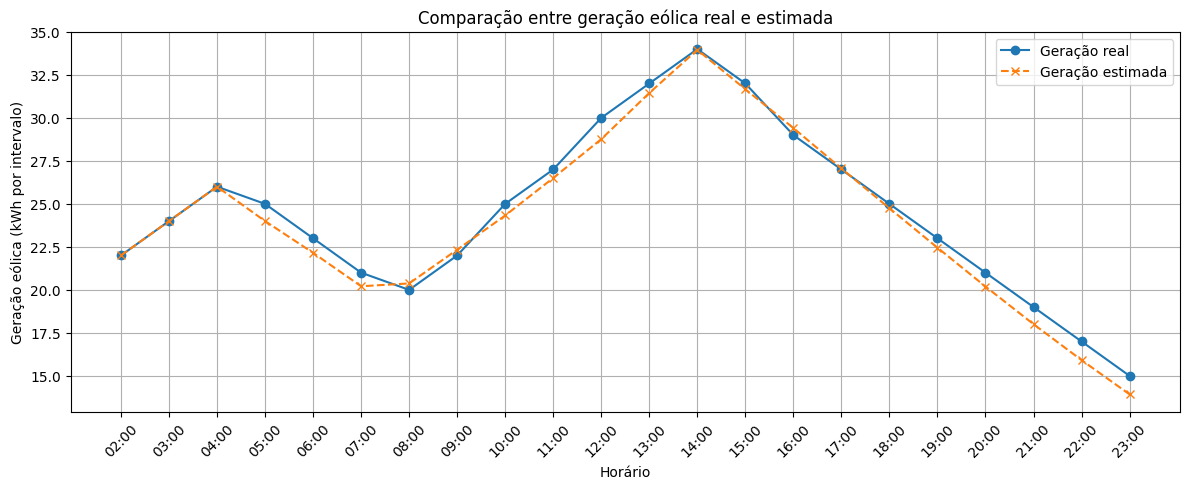


MONITORAMENTO FINALIZADO.


In [18]:
def main():
    print("\nINICIANDO O SISTEMA AURORA SIGER...")
    print(f"Total de leituras disponíveis: {len(historico_colonia)}")

    # Treina o modelo uma única vez com todo o histórico.
    modelo = treinar_modelo_eolico(historico_colonia)

    for leitura_atual in historico_colonia:
        analise = analisar_energia(leitura_atual)

        previsao = prever_geracao_eolica(
            modelo,
            leitura_atual["ambiente"]["vento"]
        )

        alertas_ambiente = analisar_ambiente(leitura_atual)
        monitoramento = monitorar_sistemas(leitura_atual)

        decisoes = tomar_decisao(
            leitura_atual,
            analise,
            previsao,
            monitoramento,
            alertas_ambiente
        )

        gerar_relatorio(
            leitura_atual,
            analise,
            previsao,
            alertas_ambiente,
            monitoramento,
            decisoes
        )

    gerar_relatorio_geral(historico_colonia)

    print("\nGERANDO VISUALIZAÇÕES...")
    gerar_grafico_previsoes(historico_colonia)

    print("\nMONITORAMENTO FINALIZADO.")


if __name__ == "__main__":
    main()